In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)

In [2]:
custom_headers = [
    'age', 'workclass', 'fnlwgt', 'education', 'education-num', 
    'marital-status', 'occupation', 'relationship', 'race', 'sex', 
    'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income'
]
data=pd.read_csv("./Adult Data/dataset/adult.data", skipinitialspace=True, names=custom_headers, header=None)

In [3]:
data.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


# Adding Missing Value

In [4]:
# Higher hours-per-week → higher probability of being missing
col = "hours-per-week"

x = data[col]

# Missingness probability increases with the value
p_missing = 0.5 * (x / x.max()) ** 2

mask = rng.random(len(data)) < p_missing

data.loc[mask, col] = np.nan

# EDA

In [5]:
print("Number of rows", len(data))
#class balance check
positive=data['income']=='<=50K'
print("Below threshold ratio:",np.mean(positive), "\nAbove Threshold ratio:", 1-np.mean(positive))


Number of rows 32561
Below threshold ratio: 0.7591904425539756 
Above Threshold ratio: 0.2408095574460244


In [6]:
#missing Values
print("Following is the stat of missing values")
print((data.isna().any()))


Following is the stat of missing values
age               False
workclass         False
fnlwgt            False
education         False
education-num     False
marital-status    False
occupation        False
relationship      False
race              False
sex               False
capital-gain      False
capital-loss      False
hours-per-week     True
native-country    False
income            False
dtype: bool


In [ ]:
#Changing the target variable to boolean
data=pd.get_dummies(data, columns=['income'], drop_first=True, dtype='int')

In [49]:
data.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income_>50K
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,United-States,0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,0


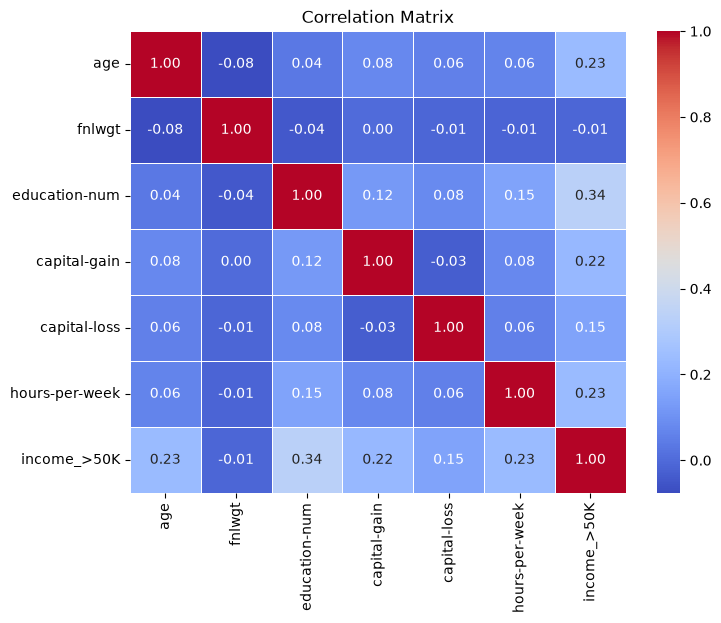

In [ ]:
numeric_data=data.select_dtypes(include=[np.number])
corr=numeric_data.corr()
# 3. Heatmap 
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

## EDA analysis for categorical variables

count    32561.000000
mean        10.080679
std          2.572720
min          1.000000
25%          9.000000
50%         10.000000
75%         12.000000
max         16.000000
Name: education-num, dtype: float64
Axes(0.125,0.11;0.775x0.77)
Skew is  -0.3116758679102297


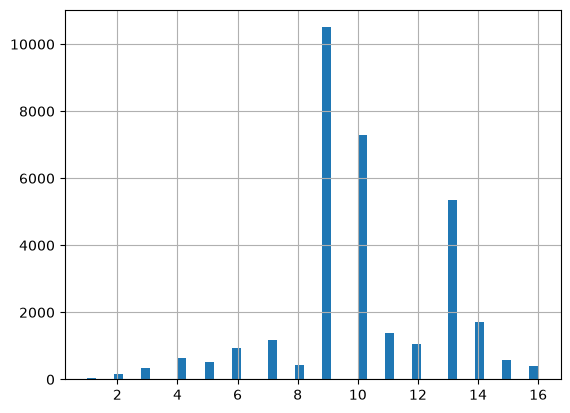

In [13]:
col='education-num'
print(data[col].describe())          # count, mean, std, min, 25%, 50%, 75%, max
print(data[col].hist(bins=50))       # distribution shape
print("Skew is ", data[col].skew())              # >0 right-skewed, <0 left-skewed

In [16]:
#This shows education and education-num have a 1-1 mapping, that is colinearity
data.groupby("education")["education-num"].agg(
    ["min", "max", "nunique", "count"]
).sort_values("min")

,min,max,nunique,count
education,,,,
Preschool,1,1,1,51
1st-4th,2,2,1,168
5th-6th,3,3,1,333
7th-8th,4,4,1,646
9th,5,5,1,514
10th,6,6,1,933
11th,7,7,1,1175
12th,8,8,1,433
HS-grad,9,9,1,10501


In [29]:
col='education-num'
uneducated=(data[col]<=9)
print("Uneducated above poverty line: ", np.mean(data.loc[uneducated, "income_>50K"]))
print("Educated above poverty line: ", np.mean(data.loc[~uneducated, "income_>50K"]))

Uneducated above poverty line:  0.13006642266503998
Educated above poverty line:  0.332565844892458


count    32561.000000
mean        38.581647
std         13.640433
min         17.000000
25%         28.000000
50%         37.000000
75%         48.000000
max         90.000000
Name: age, dtype: float64
Axes(0.125,0.11;0.775x0.77)
Skew is  0.5587433694130484


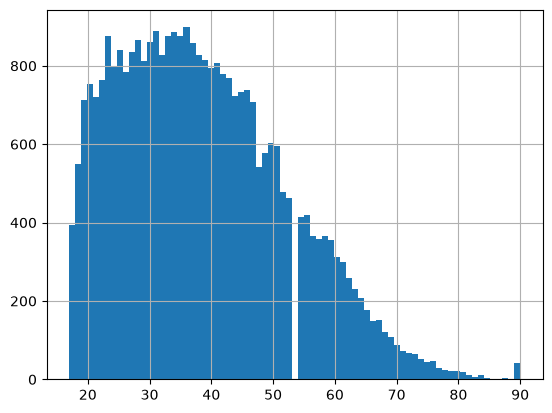

In [65]:
#But no Minors here
col='age'
print(data[col].describe())
print(data[col].hist(bins=75))       # distribution shape
print("Skew is ", data[col].skew())              # >0 right-skewed, <0 left-skewed

In [53]:
data_age=data[['age','income_>50K']]
bins=np.arange(15,91,5)
data_age['age_bins']=pd.cut(data_age['age'], bins=bins, right=False)
groups=data_age.groupby(['age_bins'])['income_>50K'].mean()
print(groups)


age_bins
[15, 20)    0.001207
[20, 25)    0.015078
[25, 30)    0.108669
[30, 35)    0.225219
[35, 40)    0.311579
[40, 45)    0.353715
[45, 50)    0.391331
[50, 55)    0.413861
[55, 60)    0.348712
[60, 65)    0.287462
[65, 70)    0.230552
[70, 75)    0.192420
[75, 80)    0.187879
[80, 85)    0.114286
[85, 90)    0.000000
Name: income_>50K, dtype: float64


In [ ]:
# workclass         False came for isna() but here we see ? is a value. LOL
# We are looking at 5% of the data in missing values
col='workclass'
gareeb_class= pd.concat([
    data[col].value_counts(),
    data[col].value_counts(normalize=True),
    data.groupby([col])['income_>50K'].mean()
], axis=1)
print(gareeb_class)

                  count  proportion  income_>50K
workclass                                       
Private           22696    0.697030     0.218673
Self-emp-not-inc   2541    0.078038     0.284927
Local-gov          2093    0.064279     0.294792
?                  1836    0.056386     0.104031
State-gov          1298    0.039864     0.271957
Self-emp-inc       1116    0.034274     0.557348
Federal-gov         960    0.029483     0.386458
Without-pay          14    0.000430     0.000000
Never-worked          7    0.000215     0.000000


In [61]:
data['fnlwgt'].describe()

count    3.256100e+04
mean     1.897784e+05
std      1.055500e+05
min      1.228500e+04
25%      1.178270e+05
50%      1.783560e+05
75%      2.370510e+05
max      1.484705e+06
Name: fnlwgt, dtype: float64

In [62]:
#Martial Status

col='marital-status'
shaadi_shudha= pd.concat([
    data[col].value_counts(),
    data[col].value_counts(normalize=True),
    data.groupby([col])['income_>50K'].mean()
], axis=1)
print(shaadi_shudha)

                       count  proportion  income_>50K
marital-status                                       
Married-civ-spouse     14976    0.459937     0.446848
Never-married          10683    0.328092     0.045961
Divorced                4443    0.136452     0.104209
Separated               1025    0.031479     0.064390
Widowed                  993    0.030497     0.085599
Married-spouse-absent    418    0.012837     0.081340
Married-AF-spouse         23    0.000706     0.434783


count    32561.000000
mean      1077.648844
std       7385.292085
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max      99999.000000
Name: capital-gain, dtype: float64



Axes(0.125,0.11;0.775x0.77)



Skew is  11.953847687699804


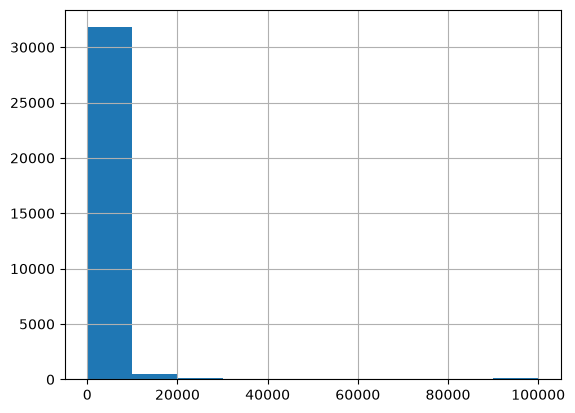

In [78]:
col='capital-gain'
print(data[col].describe())
print("\n\n")
print(data[col].hist(bins=10))       # distribution shape
print("\n\n")
print("Skew is ", data[col].skew())              # >0 right-skewed, <0 left-skewed


In [77]:
data_gains=data[['capital-gain','income_>50K']]
bins=np.arange(0,10000,500)
data_gains['bins']=pd.cut(data['capital-gain'], bins=bins, right=False)
print("\t\tcount\t\tmean")
print(pd.concat([data_gains.groupby(["bins"])['income_>50K'].count(), data_gains.groupby(["bins"])['income_>50K'].mean()], axis=1))

		count		mean
              income_>50K  income_>50K
bins                                  
[0, 500)            29857     0.206451
[500, 1000)            47     0.000000
[1000, 1500)           59     0.000000
[1500, 2000)           36     0.000000
[2000, 2500)          182     0.000000
[2500, 3000)          140     0.000000
[3000, 3500)          259     0.347490
[3500, 4000)           85     0.000000
[4000, 4500)          144     0.402778
[4500, 5000)          104     0.317308
[5000, 5500)          178     0.544944
[5500, 6000)            8     0.625000
[6000, 6500)           24     0.416667
[6500, 7000)           39     0.128205
[7000, 7500)          260     0.980769
[7500, 8000)          288     0.996528
[8500, 9000)           55     1.000000
[9000, 9500)           22     1.000000


count    32561.000000
mean        87.303830
std        402.960219
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max       4356.000000
Name: capital-loss, dtype: float64



Axes(0.125,0.11;0.775x0.77)



Skew is  4.594629121679695


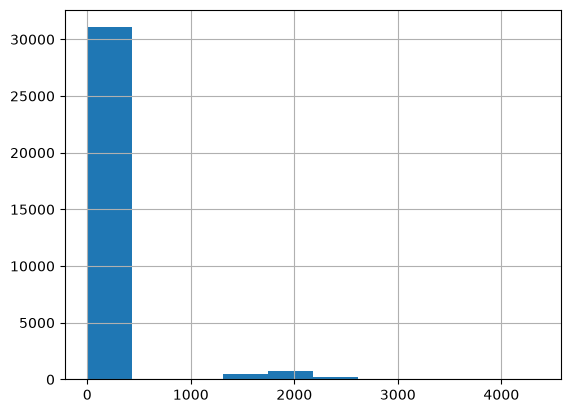

In [80]:
col='capital-loss'
print(data[col].describe())
print("\n\n")
print(data[col].hist(bins=10))       # distribution shape
print("\n\n")
print("Skew is ", data[col].skew())              # >0 right-skewed, <0 left-skewed


In [82]:
data_gains=data[['capital-loss','income_>50K']]
bins=np.arange(0,10000,500)
data_gains['bins']=pd.cut(data['capital-loss'], bins=bins, right=False)
print("\t\tcount\t\tmean")
print(pd.concat([data_gains.groupby(["bins"])['income_>50K'].count(), data_gains.groupby(["bins"])['income_>50K'].mean()], axis=1))

		count		mean
              income_>50K  income_>50K
bins                                  
[0, 500)            31053     0.227611
[500, 1000)            25     0.080000
[1000, 1500)          100     0.310000
[1500, 2000)         1058     0.565217
[2000, 2500)          281     0.402135
[2500, 3000)           33     0.787879
[3000, 3500)            2     1.000000
[3500, 4000)            6     0.166667
[4000, 4500)            3     0.000000


In [83]:
data['capital-diff']=data['capital-gain']-data['capital-loss']

count    32561.000000
mean       990.345014
std       7408.986951
min      -4356.000000
25%          0.000000
50%          0.000000
75%          0.000000
max      99999.000000
Name: capital-diff, dtype: float64



Axes(0.125,0.11;0.775x0.77)



Skew is  11.87193391898442


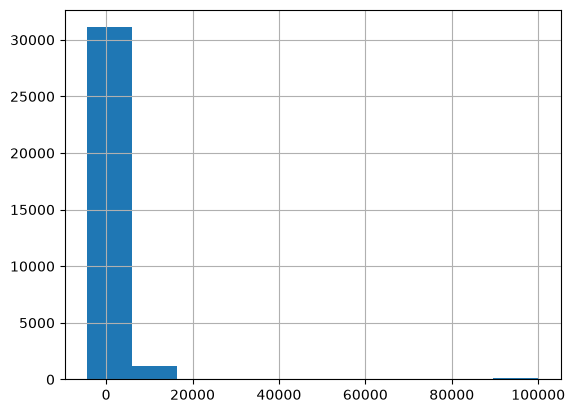

In [84]:
col='capital-diff'
print(data[col].describe())
print("\n\n")
print(data[col].hist(bins=10))       # distribution shape
print("\n\n")
print("Skew is ", data[col].skew())   

In [87]:
data_gains=data[['capital-diff','income_>50K']]
bins=np.arange(0,10000,1000)-5000
data_gains['bins']=pd.cut(data['capital-diff'], bins=bins, right=False)
print("\t\tcount\t\tmean")
print(pd.concat([data_gains.groupby(["bins"])['income_>50K'].count(), data_gains.groupby(["bins"])['income_>50K'].mean()], axis=1))

		count		mean
                income_>50K  income_>50K
bins                                    
[-5000, -4000)            3     0.000000
[-4000, -3000)            8     0.375000
[-3000, -2000)          314     0.442675
[-2000, -1000)         1158     0.543178
[-1000, 0)               36     0.055556
[0, 1000)             28385     0.189924
[1000, 2000)             95     0.000000
[2000, 3000)            322     0.000000
[3000, 4000)            344     0.261628
